# Bank Customer Churn: risk scoring, survival analysis and fairness check

**Business question.** A retail bank loses about one in five customers. Which customers are most likely to leave, when in their tenure does the risk peak, and where should a limited retention budget go?

**Data.** Public "Churn Modelling" dataset (10,000 customers of a European retail bank; France, Germany, Spain). Target `Exited` = 1 if the customer left the bank. Source and licence are documented in the README.

**Method.** (1) Reproducible pandas + DuckDB pipeline with assertion tests, (2) logistic regression / random forest / XGBoost with class-imbalance handling, stratified 5-fold CV and a 20% hold-out, isotonic calibration, a 0-100 risk score with Low/Medium/High tiers and a retention cost-benefit estimate, (3) Kaplan-Meier and Cox survival analysis on tenure, (4) fairness check by gender and age band.

All numbers below are produced by running this notebook; the same functions live in `src/churn/` and are covered by `tests/`.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import plotly.io as pio
pio.renderers.default = "png"  # static images so GitHub renders the notebook
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
from churn import config as C, data, modeling, survival, fairness, dashboard
print("seed", C.SEED, "| label", C.LABEL, "| features", len(C.FEATURES))

seed 42 | label Exited | features 13


## 1. Data pipeline

Load the raw CSV, validate it, drop identifiers, engineer three features, persist to Parquet and register the table in DuckDB so the same cleaned data can be queried with SQL.

In [2]:
raw = data.load_raw()
print(raw.shape)
pd.DataFrame({"column": list(C.DATA_DICTIONARY), "description": list(C.DATA_DICTIONARY.values()), "dtype": [str(raw[c].dtype) for c in C.DATA_DICTIONARY]})

(10000, 14)


,column,description,dtype
0,RowNumber,"Row index in the source file (identifier, drop...",int64
1,CustomerId,Unique customer identifier (dropped),int64
2,Surname,"Customer surname (dropped: free text, potentia...",object
3,CreditScore,"Credit bureau score, 350-850",int64
4,Geography,"Country of the account: France, Germany, Spain",object
5,Gender,Female / Male (used only for fairness checks a...,object
6,Age,Customer age in years,int64
7,Tenure,"Years as a customer, 0-10 (survival-analysis t...",int64
8,Balance,Account balance at snapshot,float64
9,NumOfProducts,"Number of bank products held, 1-4",int64


In [3]:
print("Cleaning rules:")
for r in data.CLEANING_RULES: print(" -", r)
df = data.build()
print(df.shape, "| churn rate", round(df[C.LABEL].mean(), 4))
df.head()

Cleaning rules:
 - Drop identifier columns RowNumber, CustomerId, Surname (no signal, leakage/proxy risk).
 - Assert no missing values; assert CustomerId unique; assert Exited in {0,1}.
 - Clip CreditScore to [300, 850]; Age to [18, 100] (no rows affected in this dataset).
 - Cast Geography/Gender to category; HasCrCard/IsActiveMember/Exited to int8.
 - Engineer BalanceSalaryRatio = Balance / EstimatedSalary, ZeroBalance = 1[Balance == 0], ProductsPerTenureYear = NumOfProducts / (Tenure + 1).
(10000, 14) | churn rate 0.2037


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,BalanceSalaryRatio,ZeroBalance,ProductsPerTenureYear
0,619,France,Female,42,2,0.0000,1,1,1,"101,348.8800",1,0.0000,1,0.3333
1,608,Spain,Female,41,1,"83,807.8600",1,0,1,"112,542.5800",0,0.7447,0,0.5000
2,502,France,Female,42,8,"159,660.8000",3,1,0,"113,931.5700",1,1.4014,0,0.3333
3,699,France,Female,39,1,0.0000,2,0,0,"93,826.6300",0,0.0000,1,1.0000
4,850,Spain,Female,43,2,"125,510.8200",1,1,1,"79,084.1000",0,1.5871,0,0.3333


In [4]:
# The processed table is also queryable from DuckDB (SQL)
data.sql("""
SELECT Geography, NumOfProducts, COUNT(*) AS customers, ROUND(AVG(Exited), 3) AS churn_rate
FROM customers GROUP BY 1, 2 ORDER BY 1, 2
""")

,Geography,NumOfProducts,customers,churn_rate
0,France,1,2514,0.2240
1,France,2,2367,0.0570
2,France,3,104,0.7880
3,France,4,29,1.0000
4,Germany,1,1349,0.4280
5,Germany,2,1040,0.1210
6,Germany,3,96,0.8960
7,Germany,4,24,1.0000
8,Spain,1,1221,0.2190
9,Spain,2,1183,0.0740


In [5]:
eda = data.eda_summary(df)
for k in ["Geography", "Gender", "NumOfProducts", "IsActiveMember", "AgeBand"]:
    print(f"\n== churn rate by {k} =="); print(eda[k].to_string(index=False))


== churn rate by Geography ==
Geography    n  churn_rate
   France 5014      0.1615
  Germany 2509      0.3244
    Spain 2477      0.1667

== churn rate by Gender ==
Gender    n  churn_rate
Female 4543      0.2507
  Male 5457      0.1646

== churn rate by NumOfProducts ==
 NumOfProducts    n  churn_rate
             1 5084      0.2771
             2 4590      0.0758
             3  266      0.8271
             4   60      1.0000

== churn rate by IsActiveMember ==
 IsActiveMember    n  churn_rate
              0 4849      0.2685
              1 5151      0.1427

== churn rate by AgeBand ==
AgeBand    n  churn_rate
  18-30 1968      0.0752
  31-40 4451      0.1209
  41-50 2320      0.3397
  51-60  797      0.5621
    60+  464      0.2478


## 2. Classification models

Three model families, each handling the 20% positive rate explicitly (`class_weight='balanced'`, `balanced_subsample`, `scale_pos_weight`). Stratified 5-fold CV on the 8,000-row training split, then a single 2,000-row stratified hold-out that is never touched during model selection.

In [6]:
res = modeling.run_all(df)
modeling.save_outputs(res)
print("train", len(res["y_train"]), "| test", len(res["y_test"]))
print("\nStratified 5-fold CV (train split):")
res["cv_table"].round(3)

train 8000 | test 2000

Stratified 5-fold CV (train split):


,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std
model,,,,,,,,,,
logistic_regression,0.7660,0.0210,0.4590,0.0300,0.3800,0.0170,0.6820,0.0380,0.4870,0.0220
random_forest,0.8590,0.0110,0.6760,0.0210,0.6160,0.0130,0.6200,0.0300,0.6170,0.0190
xgboost,0.8650,0.0100,0.7020,0.0210,0.5230,0.0080,0.7310,0.0390,0.6090,0.0150


In [7]:
print("Hold-out test set, threshold 0.5:")
res["holdout"].round(3)

Hold-out test set, threshold 0.5:


,roc_auc,pr_auc,precision,recall,f1,brier,threshold
model,,,,,,,
logistic_regression,0.7760,0.4670,0.3860,0.7030,0.4980,0.1940,0.5000
random_forest,0.8620,0.7020,0.6300,0.6310,0.6310,0.1180,0.5000
xgboost,0.8680,0.7190,0.5160,0.7590,0.6140,0.1360,0.5000


Best model by hold-out ROC AUC: xgboost


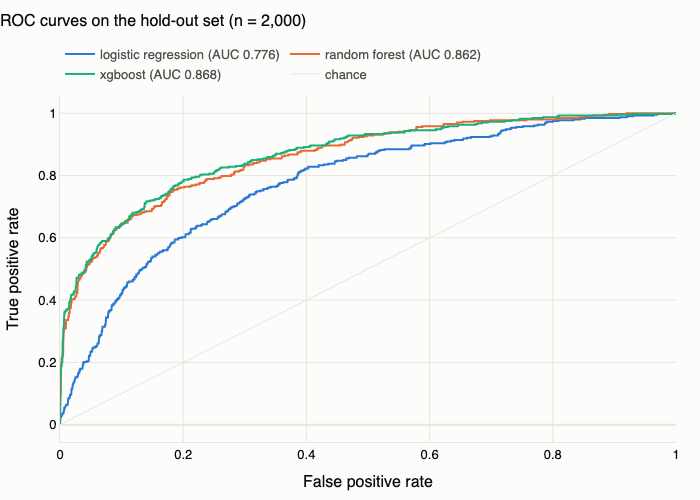

In [8]:
print("Best model by hold-out ROC AUC:", res["best_name"])
dashboard.fig_roc(res).show()

### Calibration

Weighted models output inflated probabilities. Isotonic calibration with inner 5-fold CV re-maps them so the 0-100 risk score can be read as a probability.

before: {'roc_auc': 0.868, 'pr_auc': 0.719, 'precision': 0.516, 'recall': 0.759, 'f1': 0.614, 'brier': 0.136, 'threshold': 0.5}
after:  {'roc_auc': 0.868, 'pr_auc': 0.72, 'precision': 0.801, 'recall': 0.484, 'f1': 0.603, 'brier': 0.099, 'threshold': 0.5}


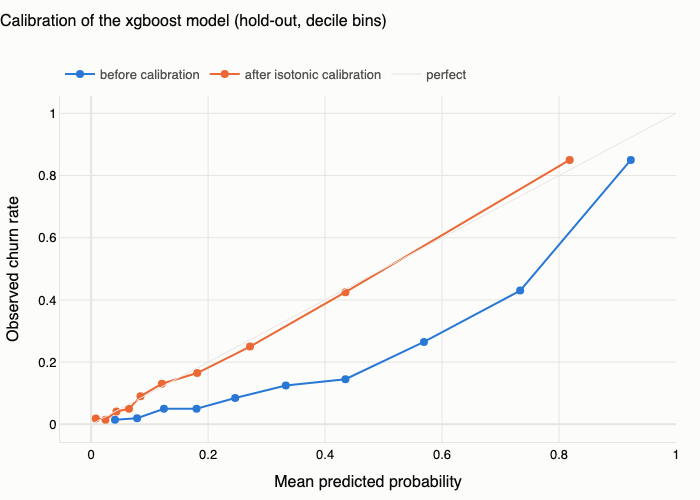

,mean_predicted,observed_rate
0,0.0080,0.0190
1,0.0250,0.0150
2,0.0430,0.0410
3,0.0650,0.0500
4,0.0840,0.0900
5,0.1210,0.1310
6,0.1810,0.1650
7,0.2720,0.2500
8,0.4350,0.4250
9,0.8180,0.8500


In [9]:
print("before:", {k: round(v, 3) for k, v in res["uncalibrated_eval"].items()})
print("after: ", {k: round(v, 3) for k, v in res["calibrated_eval"].items()})
dashboard.fig_calibration(res).show()
res["calibration_after"].round(3)

### Risk score, tiers and retention economics

Score = 100 x calibrated P(churn). Tiers: Low < 20, Medium 20-49, High >= 50. The business case assumes a retention offer costing $50 per targeted customer, $500 of 12-month value kept per retained churner and a 30% offer success rate (all editable in `config.py`).

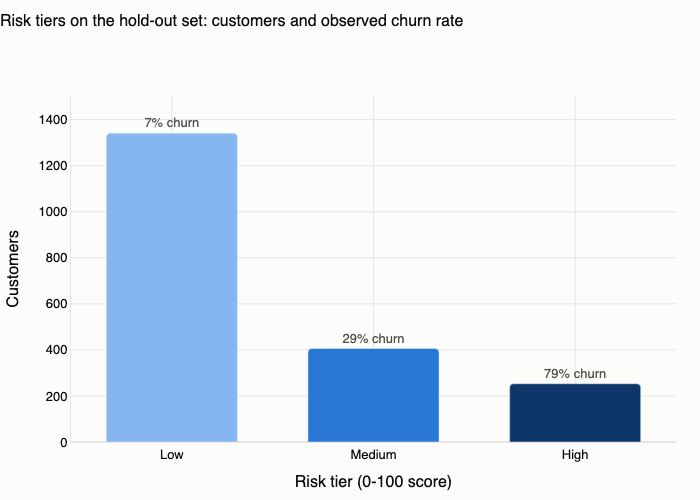

,tier,customers,churners,churn_rate,share_of_customers,share_of_churners,lift_vs_base
0,Low,1341,89,0.0660,0.6700,0.2190,0.3260
1,Medium,406,119,0.2930,0.2030,0.2920,1.4400
2,High,253,199,0.7870,0.1260,0.4890,3.8650


In [10]:
dashboard.fig_tiers(res).show()
res["tiers"].round(3)

In [11]:
res["economics"].round(1)

,tier,customers,churners,churn_rate,share_of_customers,share_of_churners,lift_vs_base,offer_cost,expected_saved_value,net_benefit,roi
0,Low,1341,89,0.1000,0.7000,0.2000,0.3000,"67,050.0000","13,350.0000","-53,700.0000",-0.8000
1,Medium,406,119,0.3000,0.2000,0.3000,1.4000,"20,300.0000","17,850.0000","-2,450.0000",-0.1000
2,High,253,199,0.8000,0.1000,0.5000,3.9000,"12,650.0000","29,850.0000","17,200.0000",1.4000


Best score cutoff on the hold-out set: 40 -> target 317 customers, recall 57%, net benefit $18,650


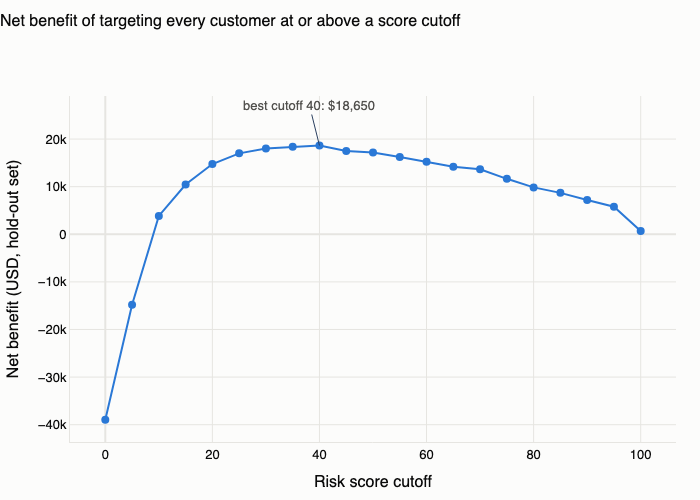

In [12]:
best = res["cutoff_sweep"].loc[res["cutoff_sweep"]["net_benefit"].idxmax()]
print(f"Best score cutoff on the hold-out set: {int(best['cutoff'])} -> target {int(best['targeted'])} customers, recall {best['recall']:.0%}, net benefit ${best['net_benefit']:,.0f}")
dashboard.fig_cutoff(res).show()

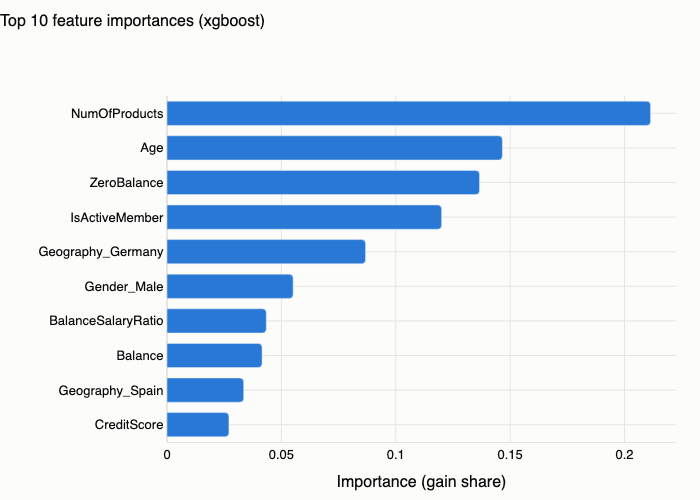

,feature,importance
0,NumOfProducts,0.2114
1,Age,0.1466
2,ZeroBalance,0.1366
3,IsActiveMember,0.1200
4,Geography_Germany,0.0868
5,Gender_Male,0.0551
6,BalanceSalaryRatio,0.0434
7,Balance,0.0416
8,Geography_Spain,0.0335
9,CreditScore,0.0271


In [13]:
dashboard.fig_importance(res).show()
res["importance"].head(10)

## 3. Survival analysis

Time = `Tenure` (years with the bank), event = `Exited`. Customers who stayed are right-censored at their current tenure. Kaplan-Meier curves are stratified by Geography, NumOfProducts and IsActiveMember with multivariate log-rank tests; a Cox proportional-hazards model (small L2 penalty) gives adjusted hazard ratios.

log-rank p-values: {'Geography': '9.14e-54', 'NumOfProducts': '9.92e-270', 'IsActiveMember': '9.27e-41'}


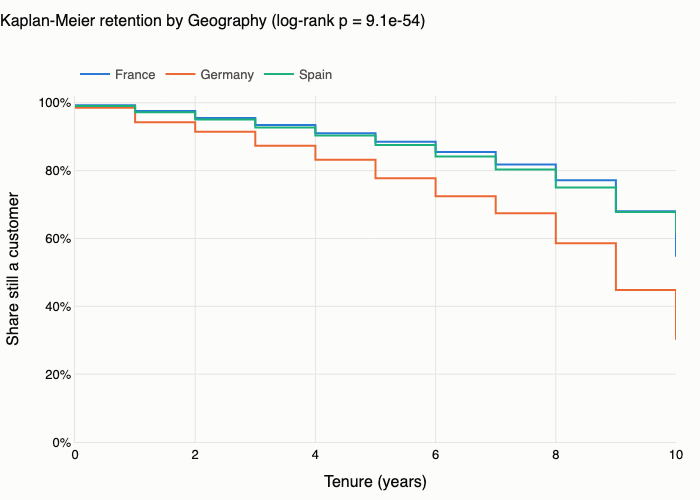

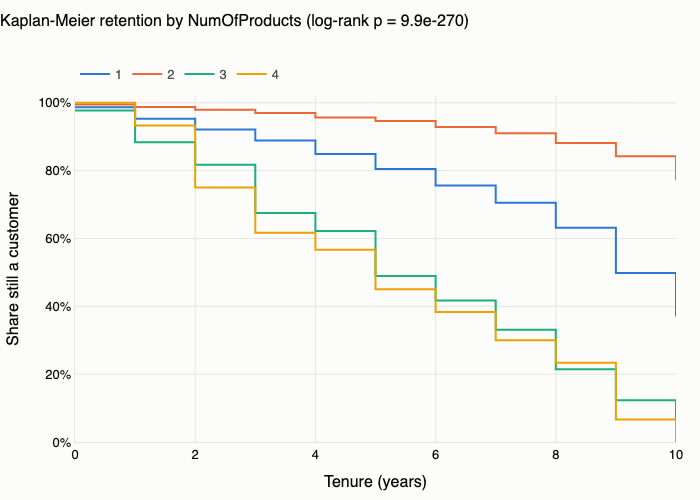

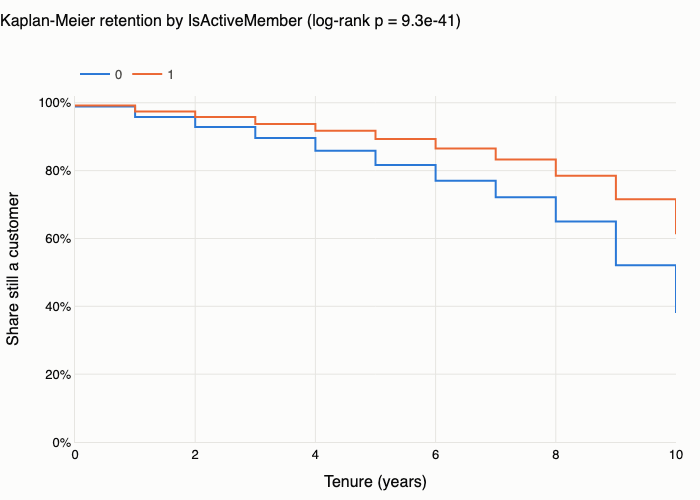

In [14]:
surv = survival.run_all(df)
survival.save_outputs(surv)
print("log-rank p-values:", {k: f"{v:.2e}" for k, v in surv["logrank_p"].items()})
for col in survival.STRATA:
    dashboard.fig_km(surv, col).show()

Peak hazard: tenure year 10 (20.6% of customers reaching that year churn in it)


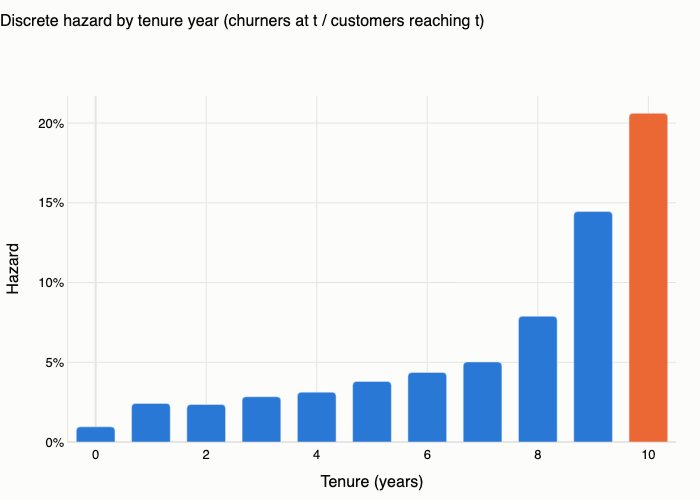

,tenure,at_risk,observed,censored,hazard
0,0.0000,10000,95,318,0.0095
1,1.0000,9587,232,803,0.0242
2,2.0000,8552,201,847,0.0235
3,3.0000,7504,213,796,0.0284
4,4.0000,6495,203,786,0.0313
5,5.0000,5506,209,803,0.0380
6,6.0000,4494,196,771,0.0436
7,7.0000,3527,177,851,0.0502
8,8.0000,2499,197,828,0.0788
9,9.0000,1474,213,771,0.1445


In [15]:
print(f"Peak hazard: tenure year {surv['peak_hazard_tenure']} ({surv['peak_hazard']:.1%} of customers reaching that year churn in it)")
dashboard.fig_hazard(surv).show()
surv["hazard"].round(4)

Cox PH model | concordance 0.7705


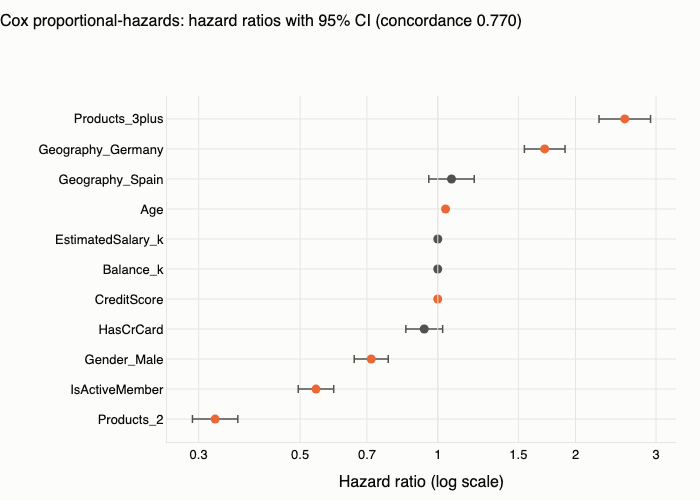

,covariate,hazard_ratio,hr_lower95,hr_upper95,p_value,significant_5pct
0,Products_3plus,2.5631,2.2514,2.9180,0.0000,True
1,Geography_Germany,1.7127,1.5461,1.8973,0.0000,True
2,Geography_Spain,1.0714,0.9557,1.2011,0.2367,False
3,Age,1.0397,1.0360,1.0434,0.0000,True
4,EstimatedSalary_k,1.0001,0.9993,1.0008,0.8438,False
5,Balance_k,0.9996,0.9988,1.0005,0.3808,False
6,CreditScore,0.9995,0.9991,1.0000,0.0328,True
7,HasCrCard,0.9340,0.8513,1.0247,0.1485,False
8,Gender_Male,0.7152,0.6565,0.7792,0.0000,True
9,IsActiveMember,0.5416,0.4953,0.5922,0.0000,True


In [16]:
print("Cox PH model | concordance", round(surv["concordance"], 4))
dashboard.fig_cox(surv).show()
surv["cox_table"].round(4)

In [17]:
print("Proportional-hazards assumption test (p < 0.05 would flag a violation):")
surv["ph_test"].round(4)

Proportional-hazards assumption test (p < 0.05 would flag a violation):


,covariate,test_statistic,p_value
0,Age,1.3859,0.2391
1,Balance_k,1.2847,0.2570
2,CreditScore,0.4498,0.5024
3,EstimatedSalary_k,3.3495,0.0672
4,Gender_Male,0.0468,0.8287
5,Geography_Germany,0.0090,0.9245
6,Geography_Spain,1.0614,0.3029
7,HasCrCard,0.4622,0.4966
8,IsActiveMember,1.7112,0.1908
9,Products_2,0.0076,0.9307


## 4. Fairness check

On the hold-out set, compare recall (true positive rate), false positive rate, precision and selection rate across Gender and age bands at the High-tier cutoff (score >= 50).

Gender gaps: {'recall_gap': 0.051, 'fpr_gap': 0.016, 'selection_rate_ratio': 0.607}


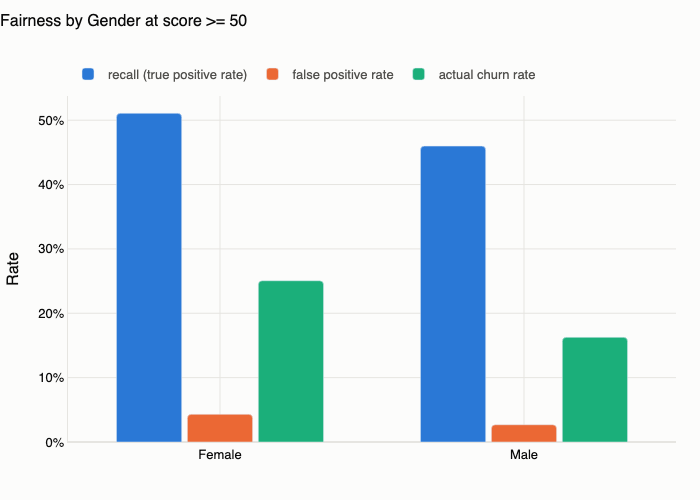

,group,n,actual_churn_rate,selection_rate,recall,false_positive_rate,precision
0,Female,930,0.2510,0.1600,0.5110,0.0430,0.7990
1,Male,1070,0.1630,0.0970,0.4600,0.0270,0.7690


In [18]:
fair = fairness.run_all(res["X_test"], res["y_test"], res["score"])
fairness.save_outputs(fair)
print("Gender gaps:", {k: round(v, 3) for k, v in fair["gender_gaps"].items()})
dashboard.fig_fairness(fair, "by_gender", "Fairness by Gender at score >= 50").show()
fair["by_gender"].round(3)

Age-band gaps: {'recall_gap': 0.673, 'fpr_gap': 0.111, 'selection_rate_ratio': 0.01}


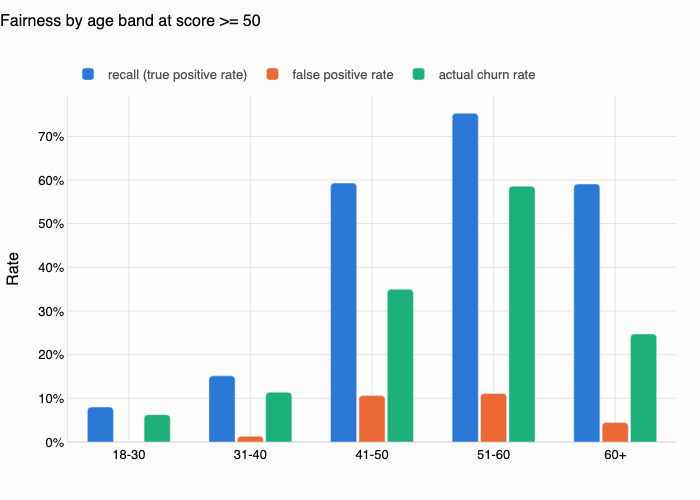

,group,n,actual_churn_rate,selection_rate,recall,false_positive_rate,precision
0,18-30,399,0.0630,0.0050,0.0800,0.0000,1.0000
1,31-40,868,0.1140,0.0290,0.1520,0.0130,0.6000
2,41-50,492,0.3500,0.2760,0.5930,0.1060,0.7500
3,51-60,152,0.5860,0.4870,0.7530,0.1110,0.9050
4,60+,89,0.2470,0.1800,0.5910,0.0450,0.8120


In [19]:
print("Age-band gaps:", {k: round(v, 3) for k, v in fair["age_gaps"].items()})
dashboard.fig_fairness(fair, "by_age", "Fairness by age band at score >= 50").show()
fair["by_age"].round(3)

**Reading.** Gender gaps are small (recall and false-positive-rate differences of a few points, both tracking the higher base rate among women). Age gaps are large: churn is concentrated in the 41-60 bands and Age is a top feature, so the model recalls most churners there and almost none under 30. A High-tier threshold therefore under-serves young churners; if the retention programme must reach them, use per-band thresholds or a separate young-customer campaign rather than a single global cutoff. See the model card for the full discussion.

## 5. Dashboard export

Writes `reports/dashboard.html`, a self-contained plotly page with every chart above plus table views.

In [20]:
path = dashboard.build(res, surv, fair)
print("dashboard written to", path)
pngs = dashboard.save_figures(res, surv, fair)
print(len(pngs), "PNG figures written to reports/figures/")

dashboard written to /Users/chenhangao/Library/Application Support/Claude/scratch-workspaces/b9fa09f8-200b-4fd4-a18a-1e8bdc059f57/f0403264-0aec-4eed-9399-9f6113cf143a/scratch-2026-10-19-984417/projects/bank-churn-risk/reports/dashboard.html


12 PNG figures written to reports/figures/
